In [1]:
%pip install python-docx pdfplumber spacy scikit-learn pandas matplotlib joblib
!python -m spacy download en_core_web_sm

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable
     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
      --------------------------------------- 0.3/12.8 MB ? eta -:--:--
     - -------------------------------------- 0.5/12.8 MB 1.2 MB/s eta 0:00:10
     ---- ----------------------------------- 1.3/12.8 MB 2.2 MB/s eta 0:00:06
     ------- -------------------------------- 2.4/12.8 MB 2.9 MB/s eta 0:00:04
     --------- ------------------------------ 3.1/12.8 MB 3.3 MB/s eta 0:00:03
     ------------ --------------------------- 3.9/12.8 MB 3.3 MB/s eta 0:00:03
     --------------- ------------------------ 5.0/12.8 MB 3.6 MB/s eta 0:00:03
     ------------------ --------------------- 5.8/12.8 MB 3.6 MB/s eta 0:00:02
     ------------------ --------------------- 6.0/12.8 MB 3.6 MB/s eta 0:00:02
     --------------------- ------------------ 6.8/12.8 MB 3.3 MB/s eta 0:0


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# %% Cell 1: Imports and load data
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from resume_parser import clean

os.makedirs("model", exist_ok=True)

CSV_PATH = "data/Resume.csv"          # change if your file is in another folder

df = pd.read_csv(CSV_PATH)
df = df[["Resume_str", "Category"]].dropna()
df = df.drop_duplicates(subset="Resume_str").reset_index(drop=True)
df["clean"] = df["Resume_str"].apply(clean)
df = df[df["clean"].str.len() > 50].reset_index(drop=True)   # drop near-empty rows

print("Total resumes:", len(df))
print("Categories   :", df["Category"].nunique())
print(df["Category"].value_counts())

Total resumes: 2481
Categories   : 24
Category
INFORMATION-TECHNOLOGY    120
BUSINESS-DEVELOPMENT      119
ADVOCATE                  118
CHEF                      118
ENGINEERING               118
ACCOUNTANT                118
FITNESS                   117
FINANCE                   117
SALES                     116
AVIATION                  116
HEALTHCARE                115
CONSULTANT                115
BANKING                   115
CONSTRUCTION              112
PUBLIC-RELATIONS          111
HR                        110
DESIGNER                  107
ARTS                      103
TEACHER                   102
APPAREL                    97
DIGITAL-MEDIA              96
AGRICULTURE                63
AUTOMOBILE                 36
BPO                        22
Name: count, dtype: int64


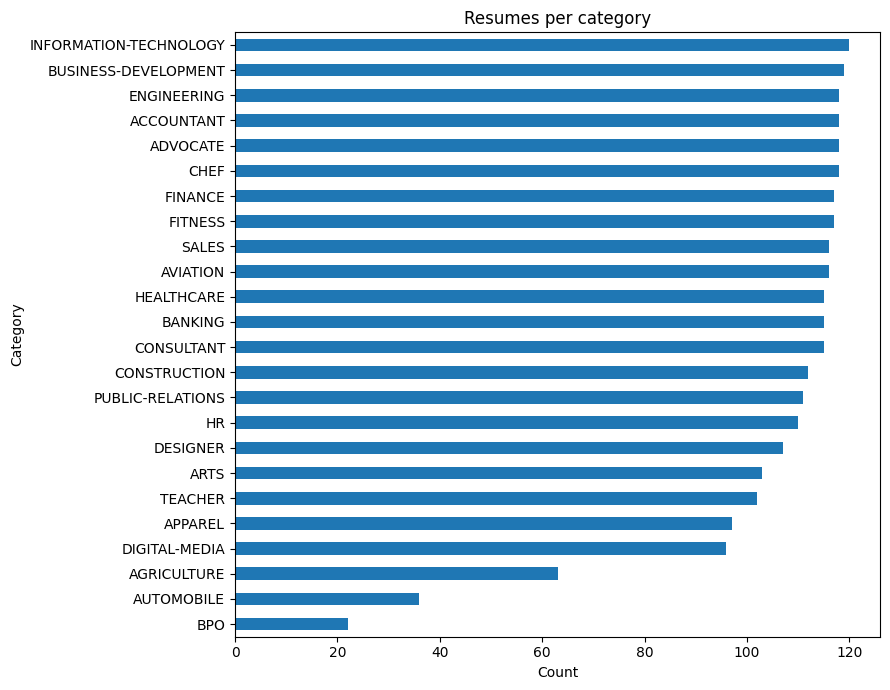

In [3]:
# %% Cell 1b: Class distribution plot (for the report)
plt.figure(figsize=(9, 7))
df["Category"].value_counts().sort_values().plot(kind="barh")
plt.title("Resumes per category")
plt.xlabel("Count")
plt.tight_layout()
plt.savefig("model/class_distribution.png", dpi=150)
plt.show()

In [4]:
# %% Cell 2: Train/test split, then tune Logistic Regression with 5-fold CV
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

y = df["Category"]
Xtr_txt, Xte_txt, ytr, yte = train_test_split(
    df["clean"], y, test_size=0.2, stratify=y, random_state=42
)
print("Train:", len(Xtr_txt), "| Test:", len(Xte_txt))

pipe = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english", sublinear_tf=True)),
    ("clf", LogisticRegression(max_iter=2000)),
])
params = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__max_features": [10000, 20000],
    "clf__C": [1, 10, 100],
}
gs = GridSearchCV(
    pipe, params,
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    scoring="f1_macro", n_jobs=-1, verbose=1,
)
gs.fit(Xtr_txt, ytr)

print("Best params      :", gs.best_params_)
print("Best CV macro F1 :", round(gs.best_score_, 3))

Train: 1984 | Test: 497
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best params      : {'clf__C': 100, 'tfidf__max_features': 10000, 'tfidf__ngram_range': (1, 2)}
Best CV macro F1 : 0.631


In [5]:
# %% Cell 3: Final features and model comparison
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

bp = gs.best_params_
vec = TfidfVectorizer(
    stop_words="english", sublinear_tf=True,
    ngram_range=bp["tfidf__ngram_range"],
    max_features=bp["tfidf__max_features"],
)
Xtr = vec.fit_transform(Xtr_txt)      # fit on training data only
Xte = vec.transform(Xte_txt)

lr = LogisticRegression(C=bp["clf__C"], max_iter=2000)
rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
svm = CalibratedClassifierCV(LinearSVC(), cv=3)

models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Logistic Regression (tuned)": lr,
    "Random Forest": rf,
    "Ensemble (LR + RF + SVM)": VotingClassifier(
        [("lr", lr), ("rf", rf), ("svm", svm)], voting="soft"
    ),
}

rows = []
for name, m in models.items():
    print("Training:", name)
    m.fit(Xtr, ytr)
    p = m.predict(Xte)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(yte, p),
        "Precision": precision_score(yte, p, average="macro", zero_division=0),
        "Recall": recall_score(yte, p, average="macro", zero_division=0),
        "F1": f1_score(yte, p, average="macro", zero_division=0),
    })

results = pd.DataFrame(rows).round(3).sort_values("F1", ascending=False)
results.to_csv("model/model_comparison.csv", index=False)
print(results.to_string(index=False))

Training: Decision Tree
Training: Logistic Regression (tuned)
Training: Random Forest
Training: Ensemble (LR + RF + SVM)
                      Model  Accuracy  Precision  Recall    F1
              Random Forest     0.759      0.764   0.703 0.690
   Ensemble (LR + RF + SVM)     0.712      0.707   0.669 0.668
Logistic Regression (tuned)     0.696      0.688   0.652 0.651
              Decision Tree     0.602      0.567   0.562 0.558


Best model: Random Forest
                        precision    recall  f1-score   support

            ACCOUNTANT       0.61      0.96      0.74        24
              ADVOCATE       0.86      0.75      0.80        24
           AGRICULTURE       1.00      0.38      0.56        13
               APPAREL       1.00      0.32      0.48        19
                  ARTS       0.75      0.14      0.24        21
            AUTOMOBILE       1.00      0.14      0.25         7
              AVIATION       0.83      0.87      0.85        23
               BANKING       0.78      0.61      0.68        23
                   BPO       0.00      0.00      0.00         4
  BUSINESS-DEVELOPMENT       0.81      0.92      0.86        24
                  CHEF       0.86      0.79      0.83        24
          CONSTRUCTION       0.91      0.91      0.91        22
            CONSULTANT       0.79      0.65      0.71        23
              DESIGNER       0.80      0.95      0.87        21
         DIGI

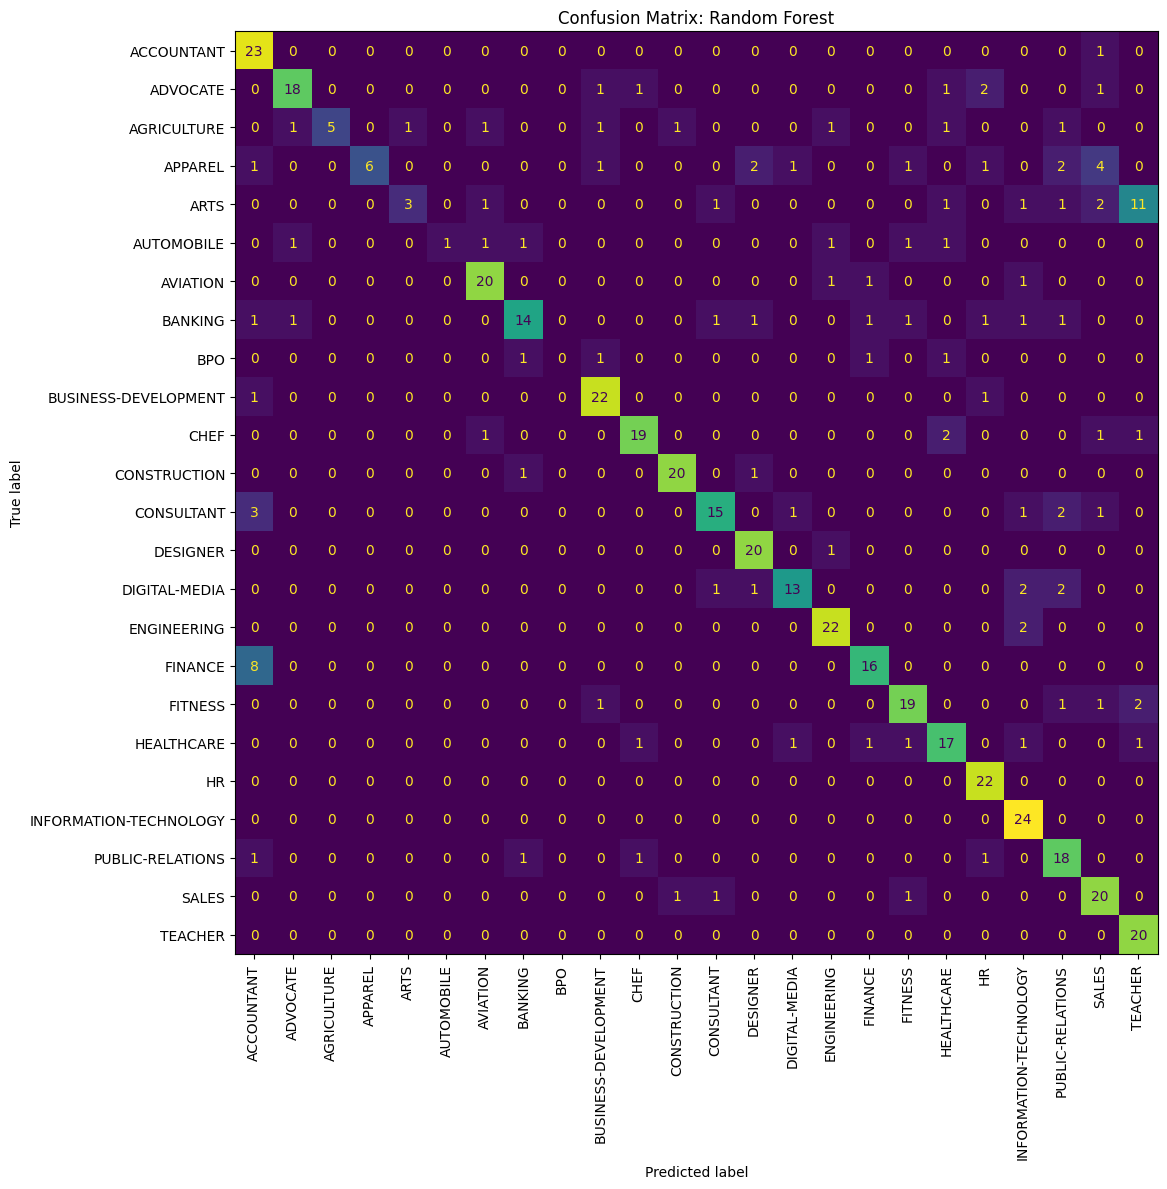

In [6]:
# %% Cell 4: Best model report and confusion matrix
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

best_name = results.iloc[0]["Model"]
best = models[best_name]
print("Best model:", best_name)

pred = best.predict(Xte)
print(classification_report(yte, pred, zero_division=0))

fig, ax = plt.subplots(figsize=(12, 12))
ConfusionMatrixDisplay.from_predictions(
    yte, pred, ax=ax, xticks_rotation=90, colorbar=False
)
plt.title(f"Confusion Matrix: {best_name}")
plt.tight_layout()
plt.savefig("model/confusion_matrix.png", dpi=150)
plt.show()

C:\Users\rohit\AppData\Roaming\Python\Python313\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\rohit\AppData\Roaming\Python\Python313\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Program Files\Python313\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Program Files\Python313\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,

K-Means clusters           : 24
Agreement with categories  : 0.261 (ARI)
Variance explained by 2 PCs: 0.035


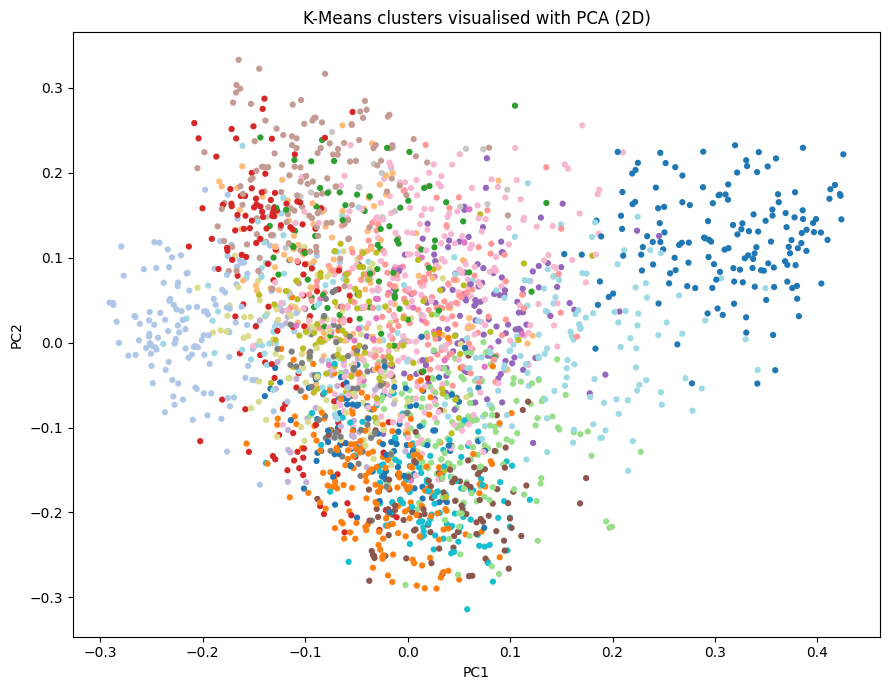

col_0                 0   1   2   3   4   5   6   7   8   9   ...  14  15  16  \
Category                                                      ...               
ACCOUNTANT            96   0   0   0   1   1   0   0   0   1  ...   0   5   1   
ADVOCATE               1   0   5   2  17   1   2   0   0   7  ...   3  30   0   
AGRICULTURE            2   9   5   1   2   0   2   0   0   3  ...   3   4   2   
APPAREL                1   4   0   7   0  14   8   6   0  13  ...   2   9   0   
ARTS                   0   1  35   4   4   4   1   1   2   5  ...   1   5   0   
AUTOMOBILE             1   2   0   1   0   2   1   0   0   3  ...   7   7   1   
AVIATION               0  10   0   0   2   5   3   0   0   5  ...   1   6   0   
BANKING                2   0   0   1   0   0  14   0   0  27  ...   3   6   0   
BPO                    1   0   0   0   0   1   5   1   0   1  ...   0   3   0   
BUSINESS-DEVELOPMENT   1   4   0   9   3   1  64   0   1  14  ...   0   7   0   

col_0                 17  1

In [7]:
# %% Cell 5: Unsupervised part (K-Means + PCA)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score

# smaller feature set so PCA stays light on memory
vec_c = TfidfVectorizer(stop_words="english", sublinear_tf=True, max_features=3000)
Xc = vec_c.fit_transform(df["clean"])

k = df["Category"].nunique()
km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xc)
print("K-Means clusters           :", k)
print("Agreement with categories  :", round(adjusted_rand_score(df["Category"], km.labels_), 3), "(ARI)")

pca = PCA(n_components=2, random_state=42)
pts = pca.fit_transform(Xc.toarray())
print("Variance explained by 2 PCs:", round(pca.explained_variance_ratio_.sum(), 3))

plt.figure(figsize=(9, 7))
plt.scatter(pts[:, 0], pts[:, 1], c=km.labels_, cmap="tab20", s=12)
plt.title("K-Means clusters visualised with PCA (2D)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.tight_layout()
plt.savefig("model/kmeans_pca.png", dpi=150)
plt.show()

# how each real category spreads across the clusters (top rows)
print(pd.crosstab(df["Category"], km.labels_).head(10))

In [8]:
# %% Cell 6: Save the best model and the vectorizer
joblib.dump(best, "model/model.pkl")
joblib.dump(vec, "model/vectorizer.pkl")
print("Saved: model/model.pkl and model/vectorizer.pkl")

Saved: model/model.pkl and model/vectorizer.pkl


In [9]:
# %% Cell 7: Quick sanity test (same steps the API will use)
sample = df["Resume_str"].iloc[0]
proba = best.predict_proba(vec.transform([clean(sample)]))[0]
i = int(proba.argmax())
print("Actual    :", df["Category"].iloc[0])
print("Predicted :", best.classes_[i], f"({proba[i] * 100:.1f}%)")

Actual    : HR
Predicted : HR (78.7%)
